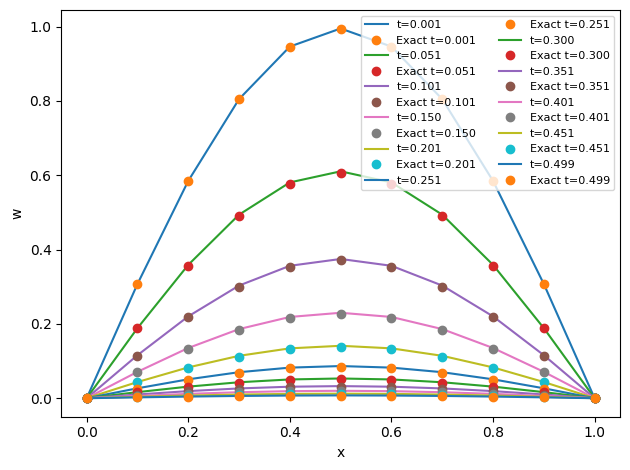

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

alpha = 1
tMax = 0.5
x0 = 0
xMax = 1

h = 0.1
k = 0.0005

n = round((xMax - x0)/h)
m = round((tMax) / k)

x = np.linspace(x0 , xMax , n+1)
t = np.linspace(0 , tMax , m+1)

w = np.zeros(n+1)
w_old = np.sin(np.pi * x)



#과제식에서의 람다
matCoef = (k* alpha**2) / h**2
A = np.zeros((n-1, n-1))

A[0,0] = 1+2*matCoef
A[0,1] = -matCoef
for i in range(1 , n-2):
  A[i,i-1] =  -matCoef
  A[i,i] =  1+2*matCoef
  A[i,i+1] =  -matCoef
A[n-2 , n-2] = 1+2*matCoef
A[n-2 , n-3] = -matCoef

cnt = 0
for iter in range(1 , m):
  w[1:n] = ThomasAlgorithm(A, n - 1, w_old[1:n])
  w_old[1:n] = w[1:n]

  if(cnt % 100 == 0 or iter == m-1):
    plt.plot(x, w, '-', label=f't={t[iter]:.3f}')
    exactS = np.exp(-np.pi ** 2 * t[iter]) * np.sin(np.pi * x)
    plt.plot(x, exactS, 'o', label=f'Exact t={t[iter]:.3f}')
    #print(w)
  cnt+=1

plt.xlabel('x')
plt.ylabel('w')
plt.legend(ncol = 2 , fontsize=8, loc='upper right')
plt.tight_layout()
plt.show()


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def ThomasAlgorithm(matrix , sizeN , b_consVector ): # Ax = b return x
  A = np.array(matrix, dtype=float)
  b = np.array(b_consVector, dtype=float)

  pivot = A[0, 0]
  A[0, 0] = 1.0
  A[0, 1] = A[0, 1] / pivot
  b[0] = b[0] / pivot

  for i in range(1, sizeN):
    factor = A[i, i-1]

    A[i, i-1] = 0.0
    A[i, i] = A[i, i] - factor * A[i-1, i]
    b[i] = b[i] - factor * b[i-1]

    pivot = A[i, i]
    A[i, i] = 1.0

    if i < sizeN - 1:
      A[i, i+1] = A[i, i+1] / pivot

    b[i] = b[i] / pivot

  x = np.zeros(sizeN)

  x[sizeN-1] = b[sizeN-1]
  #역대입법
  for i in range(sizeN - 2, -1, -1):
      x[i] = b[i] - (A[i, i+1] * x[i+1])

  return x.tolist()